# 01 — Clean the data and define churn

**Purpose.** Load the UCI Online Retail II transactions, apply the cleaning rules, describe what
remains, and turn "churn" into a label we can predict: at a cutoff date, a customer who was
active in the previous year *churns* if they make no purchase in the next N days.

Logic lives in `src/` (`data.py`, `labels.py`, with unit tests in `tests/`); this notebook only
calls it and shows results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_clean
from src.labels import build_snapshots, history_before, split_cutoffs, valid_cutoffs

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Cleaning

Rules, in order: drop rows without a customer ID; drop exact duplicate rows; drop December 2011
(the file stops on 9 Dec 2011, so the month is incomplete); drop non-product codes (postage,
manual adjustments, bank charges, test items, gift vouchers); drop zero or negative prices;
then split cancellations (invoice starting with "C") from purchases.

In [2]:
data = load_clean()
purchases, cancellations = data.purchases, data.cancellations
data.report.style.format({"rows": "{:,}", "removed": "{:,}"}).hide(axis="index")

step,rows,removed
raw rows,"1,067,371",0
drop missing customer ID,"824,364","243,007"
drop exact duplicates,"797,885","26,479"
drop on/after 2011-12-01,"780,502","17,383"
drop non-product codes,"776,915","3,587"
drop price <= 0,"776,855",60
-> purchases,"759,615",0
-> cancellations,"17,240",0


Most of the loss is the first step: about 23% of lines have no customer ID and cannot be linked
to a customer, so they are unusable for churn. Those anonymous lines are not a random sample of
sales, which is a limit worth keeping in mind: results describe *identified* customers only.

In [3]:
cust_country = purchases.groupby("customer_id")["country"].agg(lambda s: s.mode().iloc[0])
orders_per_customer = purchases.groupby("customer_id")["invoice"].nunique()
summary = pd.Series({
    "first purchase": purchases["invoice_date"].min().strftime("%Y-%m-%d"),
    "last purchase": purchases["invoice_date"].max().strftime("%Y-%m-%d"),
    "customers": f"{purchases['customer_id'].nunique():,}",
    "orders (invoices)": f"{purchases['invoice'].nunique():,}",
    "products": f"{purchases['stock_code'].nunique():,}",
    "revenue (GBP)": f"{purchases['amount'].sum():,.0f}",
    "UK share of customers": f"{(cust_country == 'United Kingdom').mean():.1%}",
    "UK share of revenue": f"{purchases.loc[purchases['country'] == 'United Kingdom', 'amount'].sum() / purchases['amount'].sum():.1%}",
    "median orders per customer": f"{orders_per_customer.median():.0f}",
    "customers with one order": f"{(orders_per_customer == 1).mean():.1%}",
    "cancelled value / purchased value": f"{-cancellations['amount'].sum() / purchases['amount'].sum():.1%}",
    "customers with any cancellation": f"{cancellations['customer_id'].nunique():,}",
}, name="value")
summary.to_frame()

,value
first purchase,2009-12-01
last purchase,2011-11-30
customers,"5,824"
orders (invoices),"35,818"
products,"4,619"
revenue (GBP),"16,556,355"
UK share of customers,91.2%
UK share of revenue,83.5%
median orders per customer,3
customers with one order,28.3%


## 2. Activity over time

,peak month
revenue,2010-11-01
active customers,2011-11-01


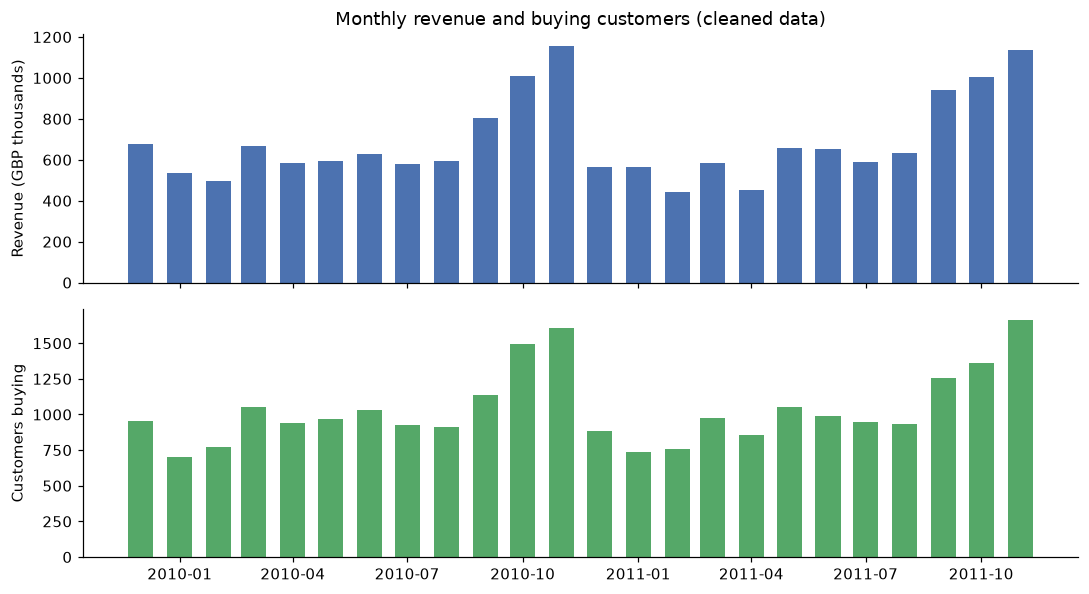

In [4]:
monthly = purchases.set_index("invoice_date").resample("MS").agg(
    {"amount": "sum", "customer_id": "nunique"}
).rename(columns={"amount": "revenue", "customer_id": "active customers"})

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].bar(monthly.index, monthly["revenue"] / 1e3, width=20, color="#4C72B0")
axes[0].set_ylabel("Revenue (GBP thousands)")
axes[1].bar(monthly.index, monthly["active customers"], width=20, color="#55A868")
axes[1].set_ylabel("Customers buying")
axes[0].set_title("Monthly revenue and buying customers (cleaned data)")
fig.tight_layout()
fig.savefig(FIG / "01_monthly_activity.png", bbox_inches="tight")
monthly.idxmax().to_frame("peak month")

Both series have a strong autumn peak (the retailer sells gifts, much of it to small shops
stocking up for Christmas). That seasonality matters for churn: a label window that covers
September–November will see many more returning customers than one covering January–March.

## 3. Churn definition and cutoff dates

There is no churn flag in the data, so we construct one with a **snapshot design**:

* **Cutoff date** — a month start. Features may only use transactions strictly before it
  (`history_before`); this is enforced and unit-tested.
* **Population** — customers with at least one purchase in the 365 days before the cutoff.
* **Label** — `churn = 1` if the customer makes no purchase in the N days from the cutoff
  (N = 90 by default; 60 and 120 as sensitivity checks).

Usable cutoffs are limited at both ends: each needs 365 days of history (so none before
1 Dec 2010) and a complete label window before the data ends on 1 Dec 2011.

In [5]:
HORIZONS = (60, 90, 120)
cutoffs = {n: valid_cutoffs(n) for n in HORIZONS}
pd.DataFrame({
    "cutoffs": {n: len(c) for n, c in cutoffs.items()},
    "first": {n: c[0].date() for n, c in cutoffs.items()},
    "last": {n: c[-1].date() for n, c in cutoffs.items()},
}).rename_axis("N (days)")

,cutoffs,first,last
N (days),,,
60,11,2010-12-01,2011-10-01
90,10,2010-12-01,2011-09-01
120,9,2010-12-01,2011-08-01


**Train/test layout (N = 90).** The last three cutoffs are the test set. A training cutoff is
only allowed if its label window closes before the first test cutoff; otherwise training labels
would contain purchases from the test period. That forces a gap of two months.

train: ['2010-12', '2011-01', '2011-02', '2011-03', '2011-04']
gap:   ['2011-05', '2011-06']
test:  ['2011-07', '2011-08', '2011-09']


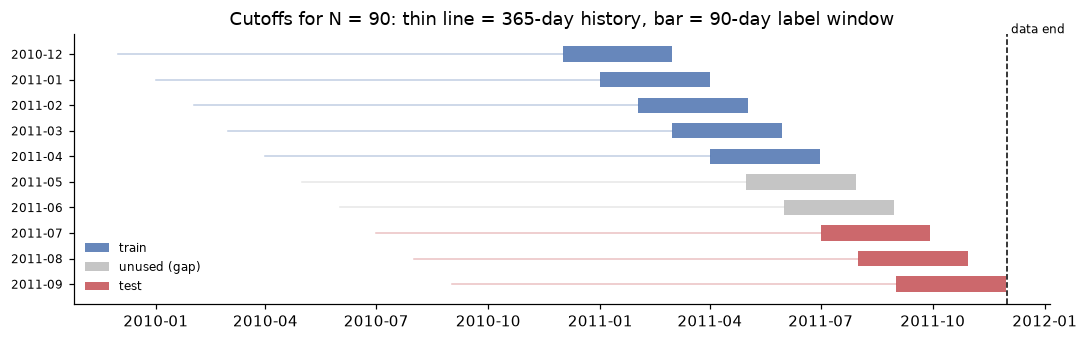

In [6]:
N = 90
train_cuts, test_cuts = split_cutoffs(cutoffs[N], horizon_days=N, n_test=3)
gap_cuts = [c for c in cutoffs[N] if c not in train_cuts + test_cuts]

fig, ax = plt.subplots(figsize=(10, 3.2))
groups = [("train", train_cuts, "#4C72B0"), ("unused (gap)", gap_cuts, "#BBBBBB"), ("test", test_cuts, "#C44E52")]
row = 0
for name, cuts, color in groups:
    for c in cuts:
        ax.barh(row, pd.Timedelta(days=N), left=c, height=0.6, color=color, alpha=0.85,
                label=name if c == cuts[0] else None)
        ax.plot([c - pd.Timedelta(days=365), c], [row, row], color=color, lw=1, alpha=0.35)
        row += 1
ax.axvline(pd.Timestamp("2011-12-01"), color="k", ls="--", lw=1)
ax.text(pd.Timestamp("2011-12-01"), -0.7, " data end", va="bottom", fontsize=8)
ax.set_yticks(range(row), [c.strftime("%Y-%m") for _, cs, _ in groups for c in cs], fontsize=8)
ax.invert_yaxis()
ax.set_title(f"Cutoffs for N = {N}: thin line = 365-day history, bar = {N}-day label window")
ax.legend(loc="lower left", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "01_cutoff_layout.png", bbox_inches="tight")
print("train:", [c.strftime("%Y-%m") for c in train_cuts])
print("gap:  ", [c.strftime("%Y-%m") for c in gap_cuts])
print("test: ", [c.strftime("%Y-%m") for c in test_cuts])

## 4. Churn rates by cutoff and horizon

In [7]:
snapshots = pd.concat(
    [build_snapshots(purchases, cutoffs[n], horizon_days=n) for n in HORIZONS], ignore_index=True
)
rates = snapshots.pivot_table(index="cutoff", columns="horizon_days", values="churn", aggfunc="mean")
sizes = snapshots[snapshots["horizon_days"] == 90].groupby("cutoff").size().rename("customers (N=90)")
table = rates.rename(columns=lambda n: f"churn N={n}").join(sizes)
table.index = table.index.strftime("%Y-%m")
table.style.format({**{f"churn N={n}": "{:.1%}" for n in HORIZONS}, "customers (N=90)": "{:,}"})

,churn N=60,churn N=90,churn N=120,customers (N=90)
cutoff,,,,
2010-12,73.3%,66.8%,60.7%,"4,239.0"
2011-01,74.9%,66.9%,60.9%,"4,205.0"
2011-02,72.8%,65.4%,59.4%,"4,221.0"
2011-03,71.1%,63.1%,57.6%,"4,260.0"
2011-04,70.1%,62.3%,57.4%,"4,318.0"
2011-05,68.1%,61.3%,57.5%,"4,319.0"
2011-06,69.3%,63.4%,56.2%,"4,324.0"
2011-07,71.3%,61.4%,53.0%,"4,314.0"
2011-08,67.2%,56.9%,47.7%,"4,326.0"


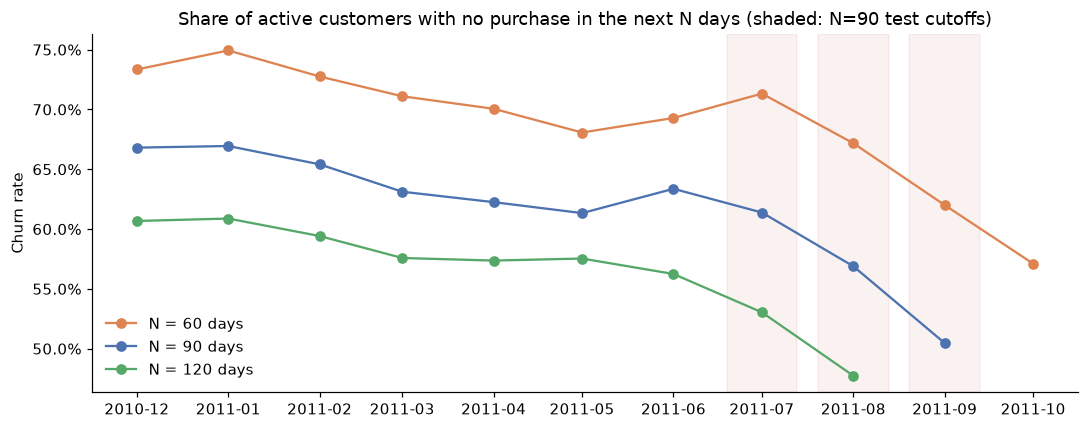

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for n, color in zip(HORIZONS, ["#DD8452", "#4C72B0", "#55A868"]):
    ax.plot(rates.index, rates[n], marker="o", color=color, label=f"N = {n} days")
for c in test_cuts:
    ax.axvspan(c - pd.Timedelta(days=12), c + pd.Timedelta(days=12), color="#C44E52", alpha=0.08)
ax.set_ylabel("Churn rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Share of active customers with no purchase in the next N days (shaded: N=90 test cutoffs)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "01_churn_rates.png", bbox_inches="tight")

In [9]:
s90 = snapshots[snapshots["horizon_days"] == 90]
period = s90["cutoff"].map(lambda c: "train" if c in train_cuts else "test" if c in test_cuts else "gap")
s90.groupby(period)["churn"].agg(snapshots="size", churn_rate="mean").loc[["train", "gap", "test"]]

,snapshots,churn_rate
cutoff,,
train,21243,0.649
gap,8643,0.624
test,12964,0.562


### Churn by number of prior orders (N = 90)

A quick look at how much a single raw variable already separates churners, to set expectations
for the baselines. Prior orders are counted from history before each cutoff only.

In [10]:
parts = []
for cutoff, snap in s90.groupby("cutoff"):
    prior = history_before(purchases, cutoff).groupby("customer_id")["invoice"].nunique()
    parts.append(snap.assign(prior_orders=snap["customer_id"].map(prior)))
by_orders = pd.concat(parts)
by_orders["prior orders"] = pd.cut(by_orders["prior_orders"], [0, 1, 2, 5, 10, float("inf")],
                                   labels=["1", "2", "3-5", "6-10", "11+"])
by_orders.groupby("prior orders", observed=True)["churn"].agg(snapshots="size", churn_rate="mean")

,snapshots,churn_rate
prior orders,,
1,11884,0.835
2,7578,0.760
3-5,11813,0.622
6-10,6830,0.388
11+,4745,0.166


In [11]:
per_customer = s90.groupby("customer_id").size()
print(f"{s90['customer_id'].nunique():,} distinct customers appear in {len(s90):,} N=90 snapshots "
      f"(median {per_customer.median():.0f} cutoffs each).")

5,224 distinct customers appear in 42,850 N=90 snapshots (median 10 cutoffs each).


## 5. Findings and implications for the next steps

1. **Churn is the majority outcome, not a rare event.** Depending on the cutoff, 50–67% of
   active customers make no purchase in the next 90 days (57–75% at 60 days, 48–61% at 120).
   Many customers buy only a few times a year, so "no purchase in 90 days" often describes
   normal behavior rather than leaving. "Predict no churn" will be a weak baseline;
   class weighting matters less than usual, and threshold choice should come from the
   profit analysis rather than from balancing classes.
2. **Seasonality shifts the base rate.** Churn falls steadily for later cutoffs because their
   label windows overlap the autumn peak. At N = 90 the test cutoffs (Jul–Sep 2011) churn at
   56%, against 65% for the training cutoffs (Dec 2010–Apr 2011). Consequences: (a) models trained on
   earlier cutoffs may be miscalibrated on the test set, so the calibration check is
   important; (b) PR-AUC depends on the base rate, so compare models within the same cutoff,
   and report lift alongside it; (c) month-of-cutoff or a seasonal feature may be worth adding.
3. **Few cutoffs.** With 365 days of history and a complete label window, N = 90 allows 10
   cutoffs: 5 for training, 2 unused as a gap, and 3 for testing. Longer horizons leave
   fewer. Shortening the history requirement for long-window features would add cutoffs.
4. **Repeated customers.** The same customer appears in many snapshots, so snapshots are not
   independent. Bootstrap confidence intervals should resample customers, not rows.
5. **Frequency is already a strong signal.** Churn falls from about 84% for one-order customers
   to about 17% for those with 11+ prior orders. The raw-RFM baseline will be hard to beat;
   the real test for engineered features is whether they add anything beyond it.
6. **Open definition choice to discuss.** The population includes anyone who bought in the
   last 365 days, including customers whose only purchase was 11 months ago. A shorter
   activity window (e.g. 180 days), or a churn horizon scaled to each customer's usual gap
   between purchases, would describe "leaving" more precisely. Both are easy to test with
   `active_days` and `horizon_days`.